In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine

In [2]:
load_dotenv("../.env")

user = os.getenv("DB_USER")
password = os.getenv("DB_PASSWORD")
host = os.getenv("DB_HOST", "localhost")

engine = create_engine(f"mysql+mysqlconnector://{user}:{password}@{host}/mydb")

df = pd.read_sql("SELECT * FROM workout", engine)
df["ex_date"] = pd.to_datetime(df["ex_date"])

In [3]:

print(df["ex_date"].min(), df["ex_date"].max())
print("training days:", df["ex_date"].nunique())
print("distinct exercises:", df["ex_name"].nunique())

2026-04-26 00:00:00 2026-05-17 00:00:00
training days: 8
distinct exercises: 37


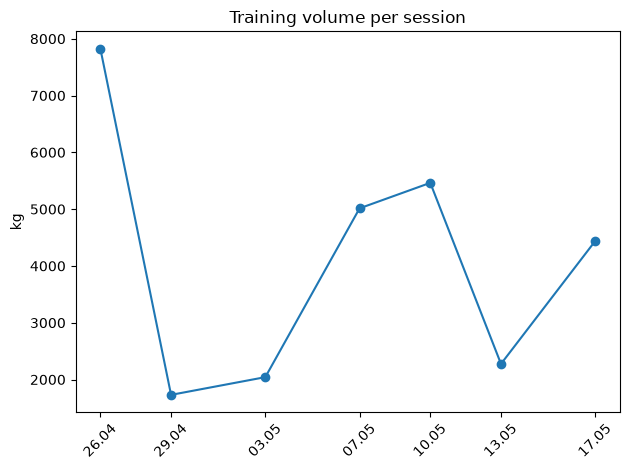

In [4]:
df["volume"] = df["weight"] * df["reps"] * df["sets"]
daily = df.groupby("ex_date")["volume"].sum(min_count=1).dropna()

fig, ax = plt.subplots()
ax.plot(daily.index, daily.values, marker="o")
ax.set_xticks(daily.index)
ax.set_xticklabels(daily.index.strftime("%d.%m"), rotation=45)
ax.set_title("Training volume per session")
ax.set_ylabel("kg")

plt.tight_layout()
plt.show()

Training volume per session (weight * reps * sets). Sessions with only bodyweight exercises are excluded. Volume ranged from 1730 to 7826 kg across 7 sessions The first session was the highest, likely because it included more exercises.

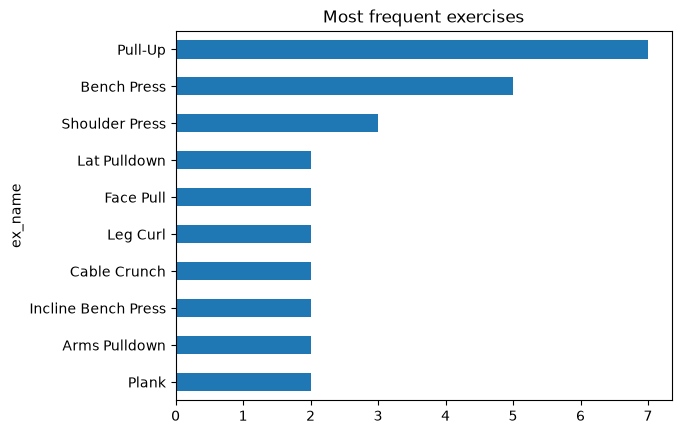

In [5]:
df["ex_name"].value_counts().head(10).plot(kind="barh", title="Most frequent exercises")

plt.gca().invert_yaxis()
plt.show()

10 most frequent exercises. Counts rows, so an exercise logged more than once in a session is counted multiple times. Counts ranged from 2 to 7, with Pull-Up the most frequent (7 entries).

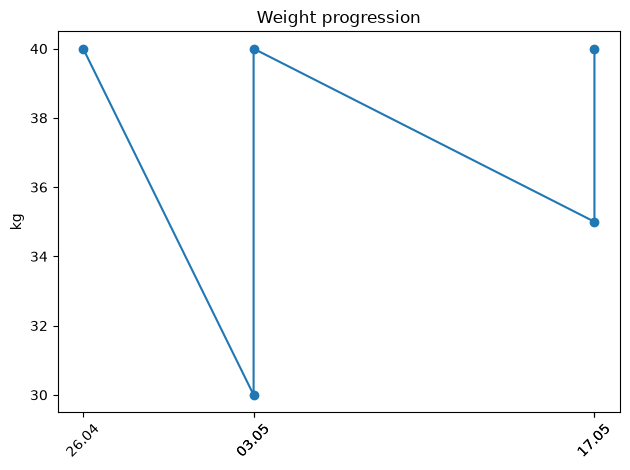

In [6]:
progress = df[df["ex_name"] == "Bench Press"]

fig, ax = plt.subplots()
ax.plot(progress["ex_date"], progress["weight"], marker="o")
ax.set_xticks(progress["ex_date"])
ax.set_xticklabels(progress["ex_date"].dt.strftime("%d.%m"), rotation=45)
ax.set_title("Weight progression")
ax.set_ylabel("kg")

plt.tight_layout()
plt.show()

Bench Press weight across the 3 sessions where it was performed. Sample too samll to draw a trend.

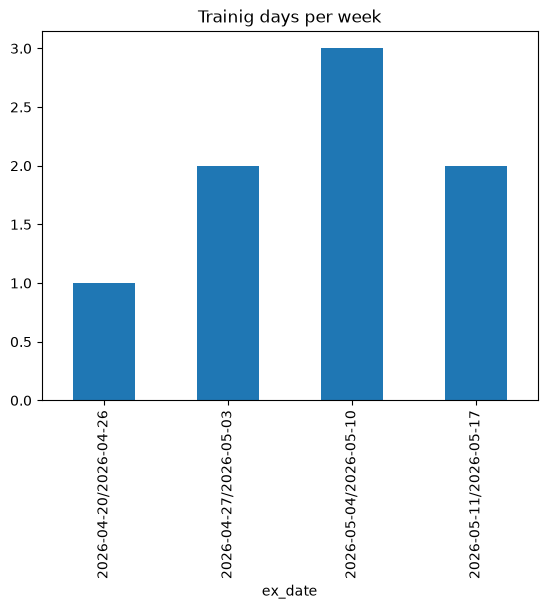

In [7]:
weekly = df.groupby(df["ex_date"].dt.to_period("W"))["ex_date"].nunique()

weekly.plot(kind="bar", title="Trainig days per week")
plt.show()

Number of training days per week. The minimum was 1 session (week of 20 Apr - 26 Apr 2026). The maximum was 3 sessions (week of 04 May - 10 May 2026). Weeks without any training are not shown.